## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

---



In [1]:
# import libraries
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

In [2]:
# download data set
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

In [5]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*




In [8]:
num = df.select_dtypes(include="number") 
cat = df.select_dtypes(exclude="number")

In [9]:
crosstab_Cat_isBestSeller = pd.crosstab(cat['category'], cat['isBestSeller'])
crosstab_Cat_isBestSeller

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


No, there is no category wher being a best-seller is more prevalent

2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.



In [ ]:
from scipy.stats import chi2_contingency

# Chi-square test for 'category' and 'isBestSeller'
_, chi2_pvalue, _, _  = chi2_contingency(crosstab_Cat_isBestSeller)

float(chi2_pvalue) <= 0.05
# If the p value is smaller than 0.05 (or alpha) we do have a correlation between 2 categorical variables
# Else, nothigness

True

we have correlation

In [ ]:
from scipy.stats.contingency import association
association(crosstab_Cat_isBestSeller, method='cramer')

0.1222829439760564

they are weakly associated because the value is in betweeen [0.1-0.2]

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.



<Axes: xlabel='category'>

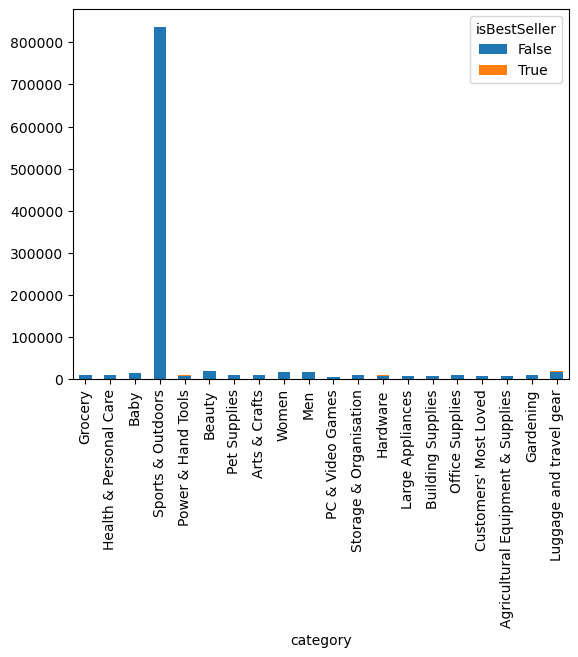

In [19]:
n= 20
top_nBestSeller = crosstab_Cat_isBestSeller.sort_values(by=True, ascending=False).head(n)
top_nBestSeller.plot(kind='bar', stacked=True) 

this plot doesn't make sense

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*



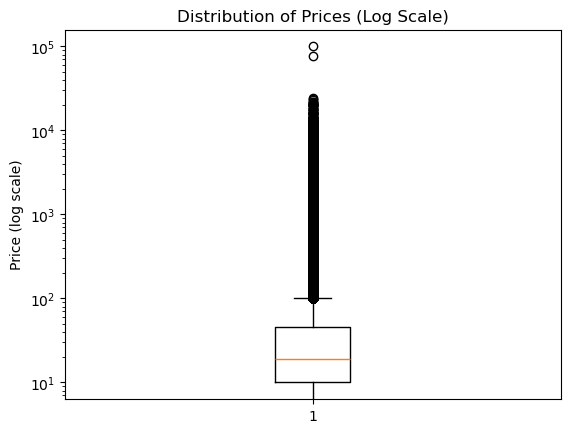

In [ ]:
plt.boxplot(df['price'])
plt.yscale('log')
plt.title('Distribution of Prices (Log Scale)')
plt.ylabel('Price (log scale)')
plt.show()

In [22]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1


lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR


df_no_outliers = df[(df['price'] >= lower_limit) & (df['price'] <= upper_limit)]

print("Before removing outliers:", df.shape[0])
print("After removing outliers:", df_no_outliers.shape[0])

Before removing outliers: 2443651
After removing outliers: 2115963


1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.



C:\Users\Alex\AppData\Local\Temp\ipykernel_20928\961493338.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x='category', y='price', palette='coolwarm')


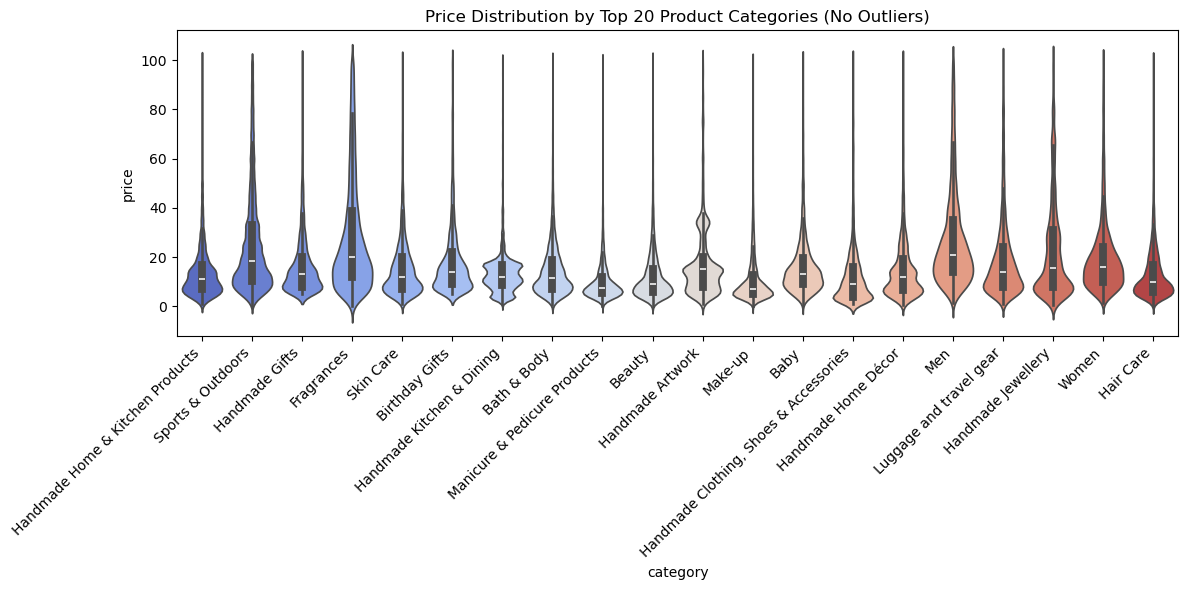

In [23]:
top20_categories = df_no_outliers['category'].value_counts().head(20).index


df_top20 = df_no_outliers[df_no_outliers['category'].isin(top20_categories)]


plt.figure(figsize=(12, 6))
sns.violinplot(data=df_top20, x='category', y='price', palette='coolwarm')
plt.xticks(rotation=45, ha='right')
plt.title('Price Distribution by Top 20 Product Categories (No Outliers)')
plt.tight_layout()
plt.show()

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.



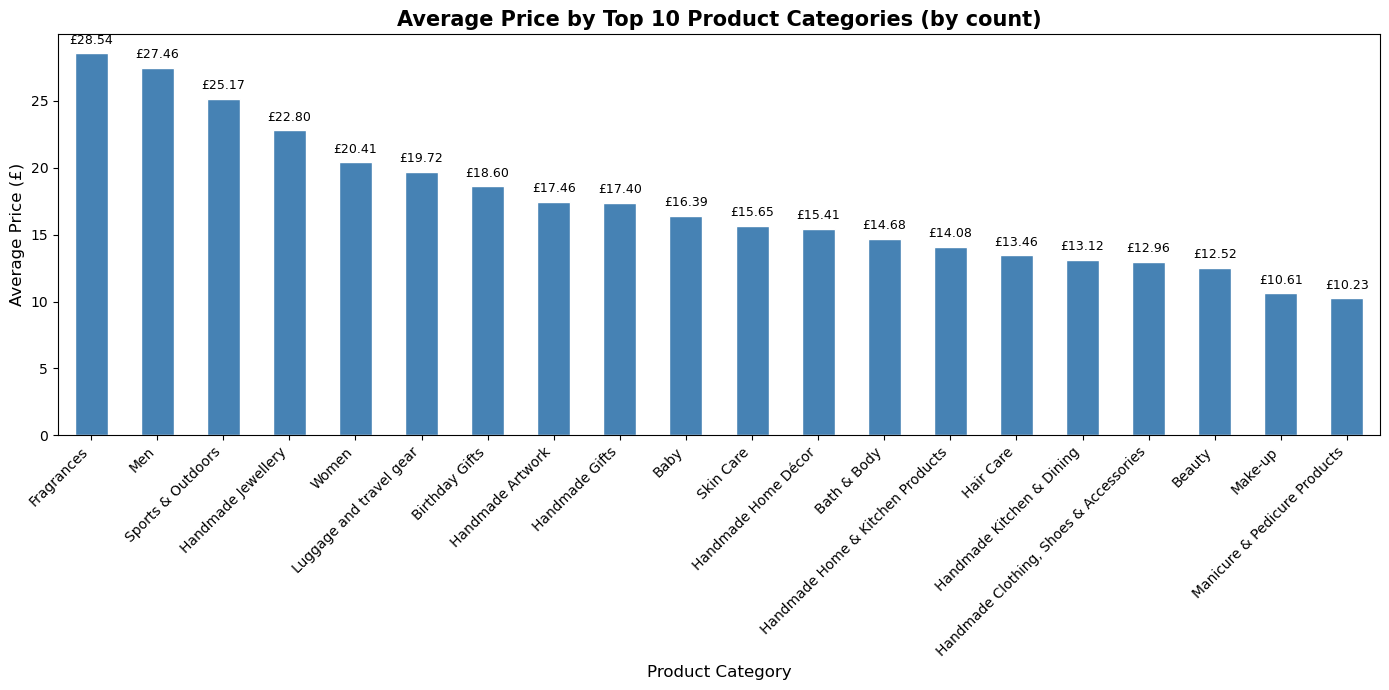

In [28]:
top10_categories = df_no_outliers['category'].value_counts().nlargest(n).reset_index().category.tolist()
top10_avg_price = df_no_outliers[df_no_outliers['category'].isin(top10_categories)].groupby('category')['price'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(14, 7))

top10_avg_price.plot(
    kind='bar',
    ax=ax,
    color='steelblue',
    edgecolor='white'
)

# Add value labels on top of each bar
for i, value in enumerate(top10_avg_price):
    ax.text(i, value + 0.5, f'£{value:.2f}', ha='center', va='bottom', fontsize=9)

ax.set_title('Average Price by Top 10 Product Categories (by count)', fontsize=15, fontweight='bold')
ax.set_xlabel('Product Category', fontsize=12)
ax.set_ylabel('Average Price (£)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

Fragances

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

---



C:\Users\Alex\AppData\Local\Temp\ipykernel_20928\1612160808.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels, patch_artist=True,


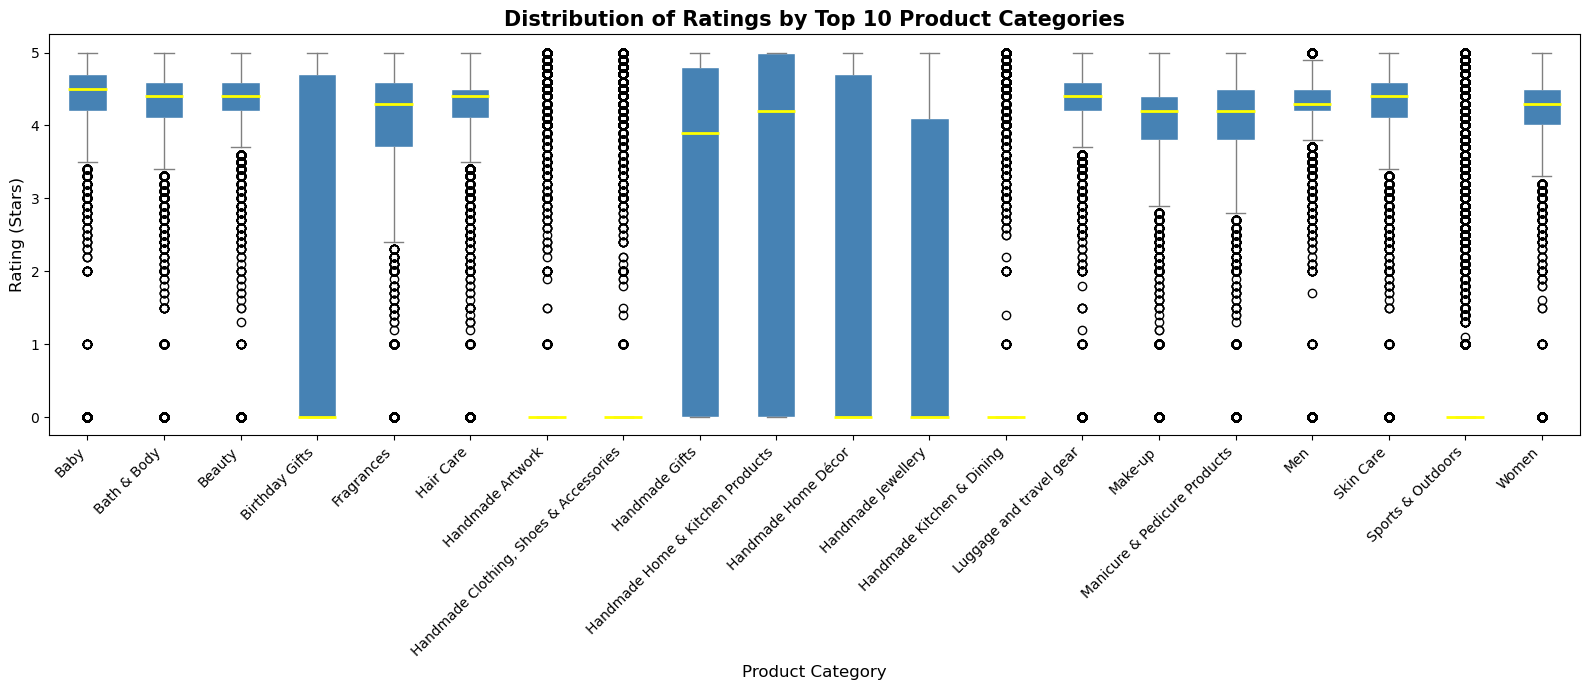

In [31]:
df_top10 = df_no_outliers[df_no_outliers['category'].isin(top10_categories)]


fig, ax = plt.subplots(figsize=(16, 7))

# Group ratings by category and collect them as lists
groups = [group['stars'].dropna().values 
          for name, group in df_top10.groupby('category')]

labels = [name for name, group in df_top10.groupby('category')]

ax.boxplot(groups, labels=labels, patch_artist=True,
           boxprops=dict(facecolor='steelblue', color='white'),
           medianprops=dict(color='yellow', linewidth=2),
           whiskerprops=dict(color='gray'),
           capprops=dict(color='gray'))

ax.set_title('Distribution of Ratings by Top 10 Product Categories', fontsize=15, fontweight='bold')
ax.set_xlabel('Product Category', fontsize=12)
ax.set_ylabel('Rating (Stars)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	


In [ ]:

correlation = df_no_outliers['price'].corr(df_no_outliers['stars'])
print(f"Correlation between Price and Stars: {correlation:.4f}")

Correlation between Price and Stars: -0.0777


no, there is not a strong correlation and it is negative (one increases the other decreases)

2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 



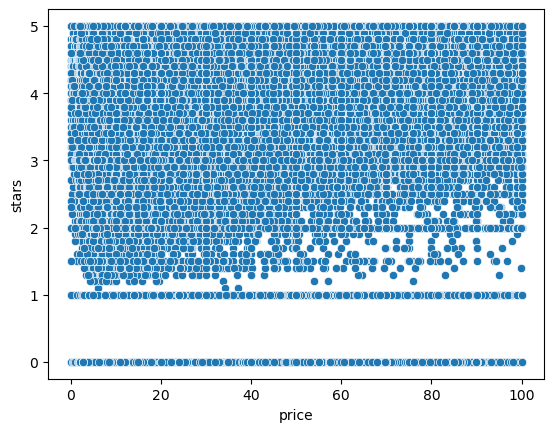

In [38]:
sns.scatterplot(data=df_no_outliers, x='price', y='stars')
plt.show()

In [40]:
cat = df_no_outliers.select_dtypes(exclude="number")
num = df_no_outliers.select_dtypes(include="number")

In [41]:
correlation_matrix = num.corr()

<Axes: >

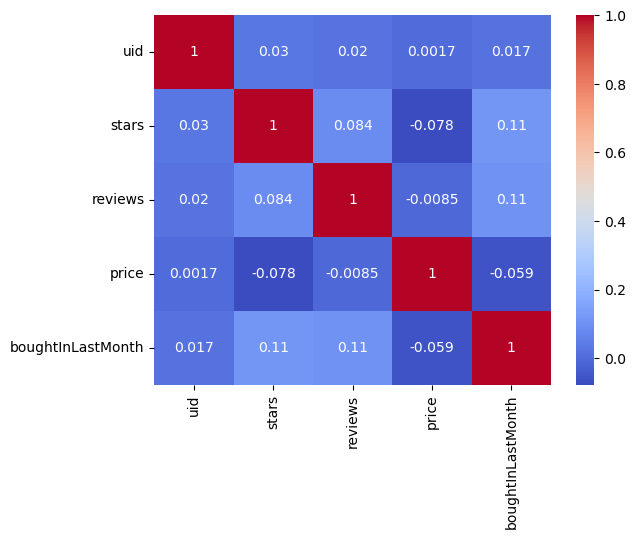

In [42]:
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

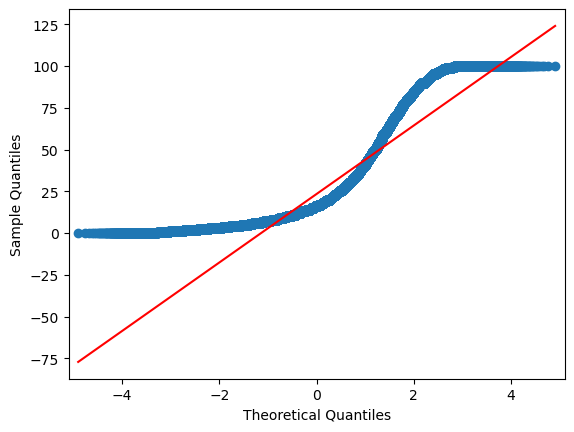

In [43]:
import statsmodels.api as sm
sm.qqplot(df_no_outliers['price'], line='s');
plt.show()